# Adult Census Income Analysis and Prediction Using Exploratory Data Analysis and Deep Learning

**Project Title:** Adult Census Income Analysis and Prediction Using Exploratory Data Analysis and Deep Learning  
**Dataset:** Adult Census Income (Kaggle: `uciml/adult-census-income`)  
**Target:** Binary classification of annual income (`<=50K` [0] vs `>50K` [1])  
**Technologies:** Python 3, pandas, NumPy, Matplotlib, Seaborn, scikit-learn, TensorFlow / Keras, Jupyter Notebook

---

### Project Objectives
1. Perform comprehensive exploratory data analysis (EDA) across demographic, occupational, and educational dimensions.
2. Characterize class imbalance, data distributions, missing value representations (`?`), and outliers.
3. Establish a strictly leak-free preprocessing pipeline using a stratified 70:15:15 Train/Val/Test split.
4. Construct, tune, and evaluate a Multilayer Perceptron (MLP) deep learning classifier in TensorFlow/Keras.
5. Analyze feature importance via permutation importance and evaluate demographic bias and predictive limitations.


## 1. Imports and Environment Setup

In [1]:
import os
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report, log_loss
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Configure global visualization aesthetics
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 150
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["savefig.bbox"] = "tight"

# Reproducible random seeds
def set_seeds(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)

set_seeds(42)
print("Libraries imported successfully!")
print(f"TensorFlow Version: {tf.__version__}")


Libraries imported successfully!
TensorFlow Version: 2.21.0


## 2. Dataset Acquisition, Loading & Structural Verification

The dataset originates from the 1994 U.S. Census database (extracted by Barry Becker) and is acquired from Kaggle (`uciml/adult-census-income`).
Here we verify dimensions, field count (>= 15 fields), data types, and initial records.


In [2]:
# Determine relative path to adult.csv
possible_paths = [
    Path("../data/adult.csv"),
    Path("data/adult.csv"),
    Path("../../data/adult.csv"),
]
data_path = next(p for p in possible_paths if p.is_file())
print(f"Loading dataset from: {data_path.resolve()}")

df_raw = pd.read_csv(data_path)
print(f"Dataset Dimensions: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
assert df_raw.shape[1] >= 15, "Expected at least 15 columns!"

print("\nFirst 5 rows:")
df_raw.head()


Loading dataset from: D:\Documents\Academics\EDA\Ass_2\EDA_Adult_Income_Project\data\adult.csv
Dataset Dimensions: 32,561 rows x 15 columns

First 5 rows:


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


## 3. Data Inspection, Cleaning & Target Normalization

In the raw dataset:
1. Missing values are disguised as `'?'` characters in categorical columns (`workclass`, `occupation`, `native.country`).
2. Leading/trailing whitespaces exist in string fields.
3. Duplicate records must be detected and handled.
4. The target column (`income`) must be normalized into binary integers: `0` for `<=50K` and `1` for `>50K`.


In [3]:
# Strip whitespace from string columns
df_clean = df_raw.copy()
for col in df_clean.select_dtypes(include=["object"]).columns:
    df_clean[col] = df_clean[col].astype(str).str.strip()

# Replace '?' with np.nan
df_clean = df_clean.replace("?", np.nan)

# Duplicate inspection and handling
dup_count = df_clean.duplicated().sum()
print(f"Identified Duplicate Rows: {dup_count}")
df_clean = df_clean.drop_duplicates().reset_index(drop=True)
print(f"Rows after duplicate removal: {len(df_clean):,}")

# Target encoding
target_col = [c for c in df_clean.columns if "income" in c.lower()][0]
df_clean["target"] = df_clean[target_col].str.rstrip(".").apply(lambda x: 1 if ">50k" in x.lower() else 0)

print("\nTarget Class Distribution:")
target_summary = pd.DataFrame({
    "Count": df_clean["target"].value_counts(),
    "Percentage (%)": (df_clean["target"].value_counts(normalize=True) * 100).round(2)
}, index=[0, 1])
target_summary.index = ["<=50K (0)", ">50K (1)"]
target_summary


Identified Duplicate Rows: 24
Rows after duplicate removal: 32,537

Target Class Distribution:


C:\Users\cskar\AppData\Local\Temp\ipykernel_24700\380893434.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_clean.select_dtypes(include=["object"]).columns:


,Count,Percentage (%)
<=50K (0),24698,75.91
>50K (1),7839,24.09


## 4. Missing Value Profiling and Outlier Inspection

We calculate the exact missing value percentages after converting `'?'` to `NaN`, and apply the Interquartile Range (IQR) rule to inspect extreme numerical values. Valid extremes (e.g., long workweeks or high capital gains) are preserved to retain real-world signals.


In [4]:
# Missing value profiling
missing_df = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage (%)": (df_clean.isnull().sum() / len(df_clean) * 100).round(2),
    "Data Type": df_clean.dtypes
})
missing_df = missing_df[missing_df["Missing Count"] > 0].sort_values(by="Missing Count", ascending=False)
print("Columns with Missing Values:")
display(missing_df)

# Outlier inspection using IQR
num_cols = list(df_clean.select_dtypes(include=[np.number]).columns)
num_cols = [c for c in num_cols if c != "target"]

outlier_stats = []
for c in num_cols:
    s = df_clean[c].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    n_outliers = ((s < lower_bound) | (s > upper_bound)).sum()
    outlier_stats.append({
        "Feature": c,
        "Q1": q1,
        "Median": s.median(),
        "Q3": q3,
        "IQR": iqr,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": n_outliers,
        "Outlier Pct (%)": round((n_outliers / len(s)) * 100, 2)
    })

pd.DataFrame(outlier_stats)


Columns with Missing Values:


,Missing Count,Missing Percentage (%),Data Type
occupation,1843,5.66,str
workclass,1836,5.64,str
native.country,582,1.79,str


,Feature,Q1,Median,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Pct (%)
0,age,28.0,37.0,48.0,20.0,-2.0,78.0,142,0.44
1,fnlwgt,117827.0,178356.0,236993.0,119166.0,-60922.0,415742.0,993,3.05
2,education.num,9.0,10.0,12.0,3.0,4.5,16.5,1193,3.67
3,capital.gain,0.0,0.0,0.0,0.0,0.0,0.0,2712,8.34
4,capital.loss,0.0,0.0,0.0,0.0,0.0,0.0,1519,4.67
5,hours.per.week,40.0,40.0,45.0,5.0,32.5,52.5,9002,27.67


## 5. Statistical Summaries (Univariate, Bivariate & Multivariate)

Here we compute central tendency (mean, median), dispersion (standard deviation, IQR), and skewness for numerical variables, as well as category frequencies.


In [5]:
# Numerical summary
num_summary = []
for c in num_cols:
    s = df_clean[c].dropna()
    num_summary.append({
        "Feature": c,
        "Mean": round(s.mean(), 2),
        "Std": round(s.std(), 2),
        "Min": s.min(),
        "25%": s.quantile(0.25),
        "50% (Median)": s.median(),
        "75%": s.quantile(0.75),
        "Max": s.max(),
        "IQR": s.quantile(0.75) - s.quantile(0.25),
        "Skewness": round(s.skew(), 2)
    })
display(pd.DataFrame(num_summary))

# Correlation matrix
corr_matrix = df_clean[num_cols + ["target"]].corr().round(3)
display(corr_matrix)


,Feature,Mean,Std,Min,25%,50% (Median),75%,Max,IQR,Skewness
0,age,38.59,13.64,17,28.0,37.0,48.0,90,20.0,0.56
1,fnlwgt,189780.85,105556.47,12285,117827.0,178356.0,236993.0,1484705,119166.0,1.45
2,education.num,10.08,2.57,1,9.0,10.0,12.0,16,3.0,-0.31
3,capital.gain,1078.44,7387.96,0,0.0,0.0,0.0,99999,0.0,11.95
4,capital.loss,87.37,403.10,0,0.0,0.0,0.0,4356,0.0,4.59
5,hours.per.week,40.44,12.35,1,40.0,40.0,45.0,99,5.0,0.23


,age,fnlwgt,education.num,capital.gain,capital.loss,hours.per.week,target
age,1.000,-0.076,0.036,0.078,0.058,0.069,0.234
fnlwgt,-0.076,1.000,-0.043,0.000,-0.010,-0.019,-0.010
education.num,0.036,-0.043,1.000,0.123,0.080,0.148,0.335
capital.gain,0.078,0.000,0.123,1.000,-0.032,0.078,0.223
capital.loss,0.058,-0.010,0.080,-0.032,1.000,0.054,0.151
hours.per.week,0.069,-0.019,0.148,0.078,0.054,1.000,0.230
target,0.234,-0.010,0.335,0.223,0.151,0.230,1.000


## 6. Exploratory Data Analysis Visualizations

We generate the mandatory six visualizations along with supplementary domain charts:
- **Visualization 1:** Income Class Distribution (Imbalance analysis)
- **Visualization 2:** Age Distribution (Right-skew & workforce peaks)
- **Visualization 3:** Educational Attainment Frequency
- **Visualization 4:** Weekly Working Hours by Income Category
- **Visualization 5:** Education vs. Income Proportion Relationship
- **Visualization 6:** Numerical Feature Correlation Heatmap
- **Visualization 7:** Non-zero Capital Gains/Losses by Income
- **Visualization 8:** High-Income Proportion Across Occupations


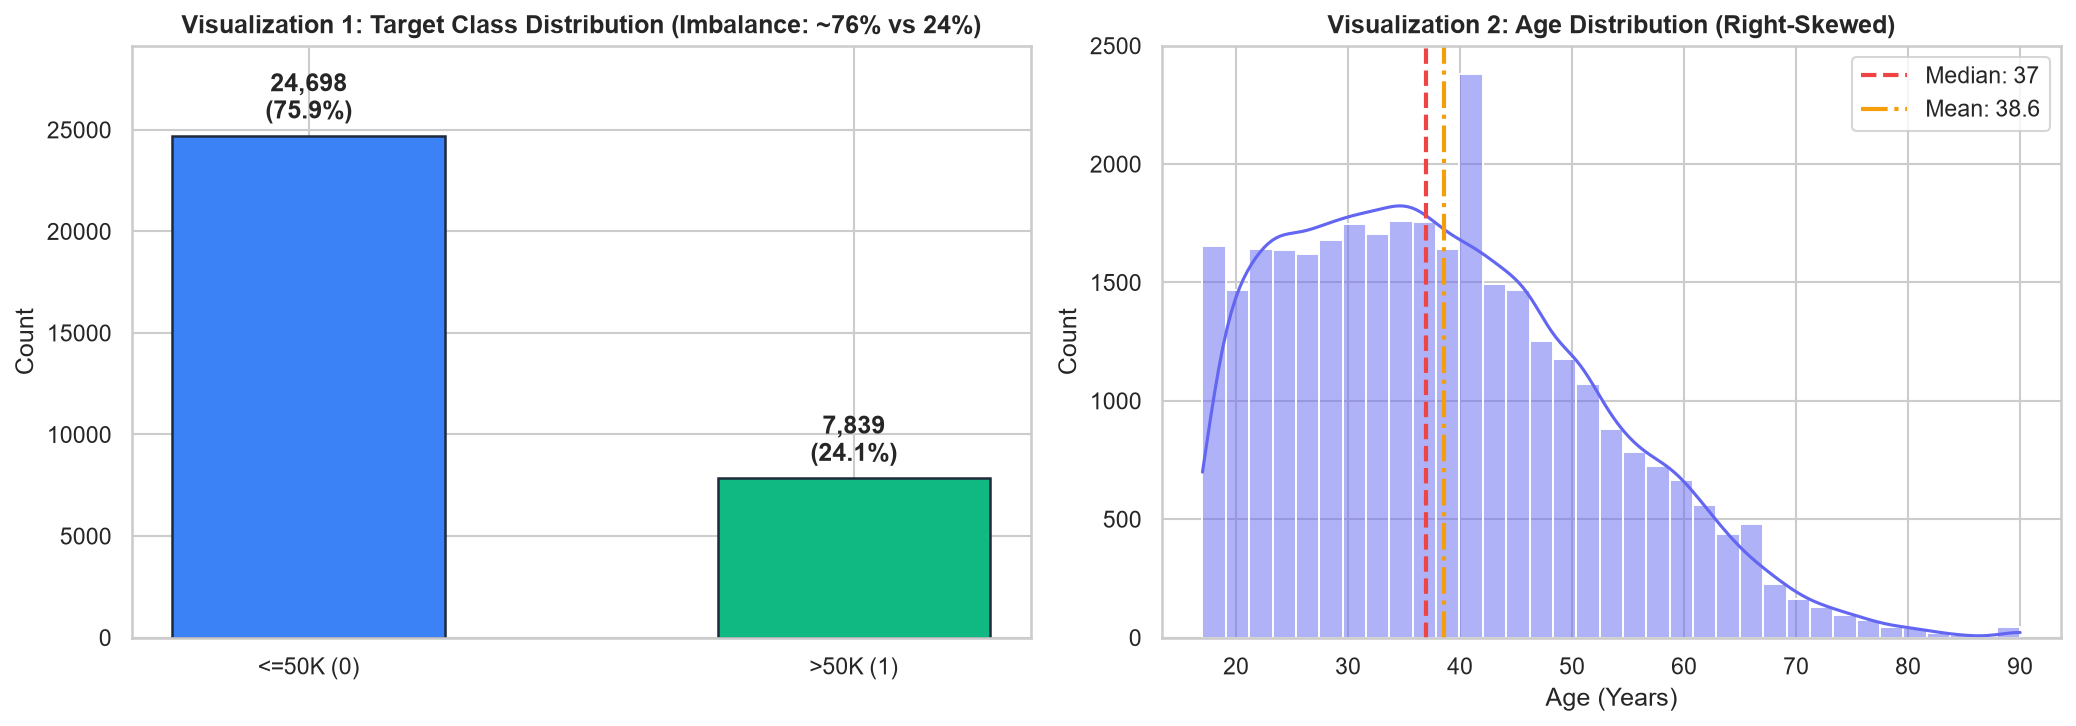

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Viz 1: Income Distribution
counts = df_clean["target"].value_counts()
labels = ["<=50K (0)", ">50K (1)"]
colors = ["#3B82F6", "#10B981"]
bars = axes[0].bar(labels, counts.values, color=colors, width=0.5, edgecolor="#1E293B", linewidth=1.2)
for bar in bars:
    h = bar.get_height()
    pct = (h / len(df_clean) * 100)
    axes[0].annotate(f"{h:,}\n({pct:.1f}%)", xy=(bar.get_x() + bar.get_width() / 2, h),
                     xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", fontweight="bold")
axes[0].set_title("Visualization 1: Target Class Distribution (Imbalance: ~76% vs 24%)", fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_ylim(0, max(counts.values) * 1.18)

# Viz 2: Age Distribution
sns.histplot(df_clean["age"], kde=True, bins=35, color="#6366F1", ax=axes[1])
axes[1].axvline(df_clean["age"].median(), color="#EF4444", linestyle="--", linewidth=2, label=f"Median: {df_clean['age'].median():.0f}")
axes[1].axvline(df_clean["age"].mean(), color="#F59E0B", linestyle="-.", linewidth=2, label=f"Mean: {df_clean['age'].mean():.1f}")
axes[1].set_title("Visualization 2: Age Distribution (Right-Skewed)", fontweight="bold")
axes[1].set_xlabel("Age (Years)")
axes[1].legend()

plt.tight_layout()
plt.show()


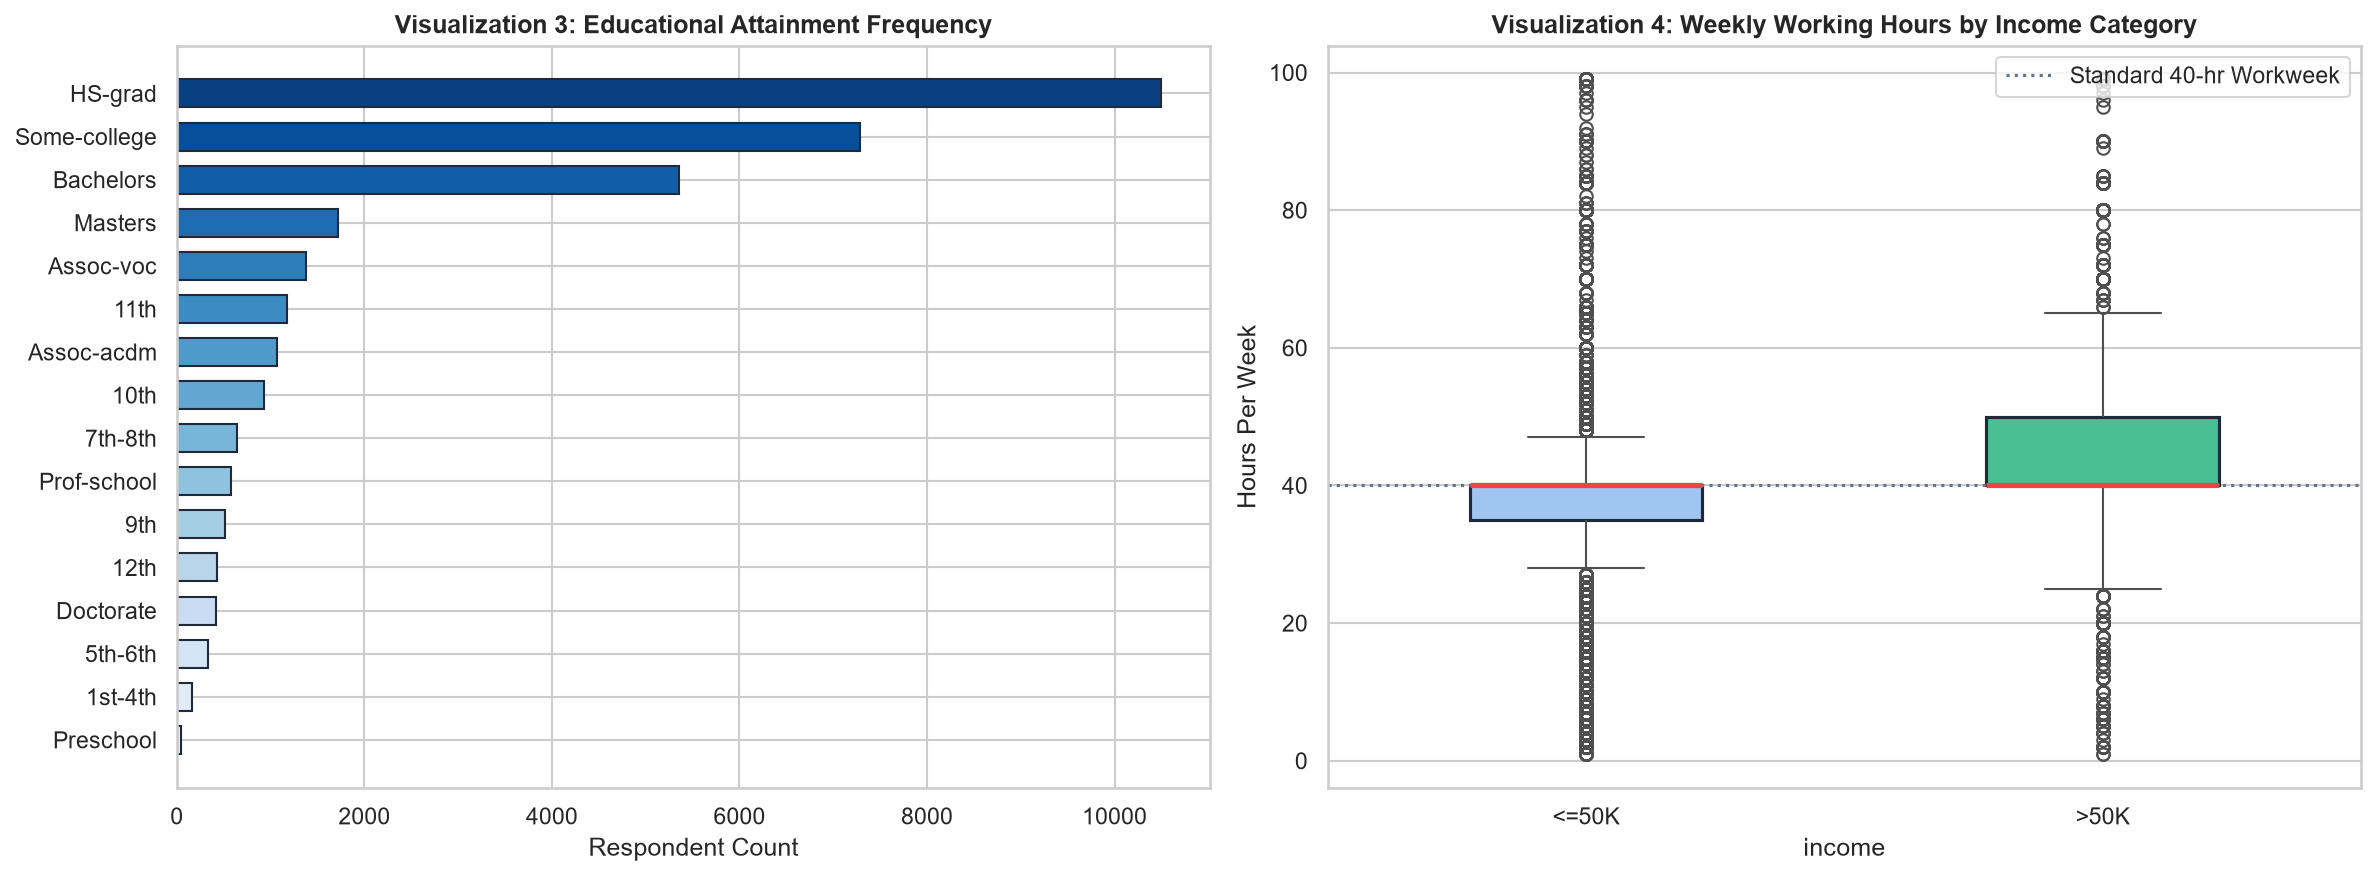

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Viz 3: Education Frequency
edu_counts = df_clean["education"].value_counts()
palette = sns.color_palette("Blues_r", n_colors=len(edu_counts))
axes[0].barh(edu_counts.index, edu_counts.values, color=palette, edgecolor="#1E293B", height=0.65)
axes[0].invert_yaxis()
axes[0].set_title("Visualization 3: Educational Attainment Frequency", fontweight="bold")
axes[0].set_xlabel("Respondent Count")

# Viz 4: Hours per week by Income
sns.boxplot(
    data=df_clean, x="income", y="hours.per.week", hue="income", legend=False,
    palette={"<=50K": "#93C5FD", ">50K": "#34D399"},
    boxprops=dict(edgecolor="#1E293B", linewidth=1.5),
    medianprops=dict(color="#EF4444", linewidth=2.5),
    width=0.45, ax=axes[1]
)
axes[1].axhline(40, color="#64748B", linestyle=":", linewidth=1.5, label="Standard 40-hr Workweek")
axes[1].set_title("Visualization 4: Weekly Working Hours by Income Category", fontweight="bold")
axes[1].set_ylabel("Hours Per Week")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()


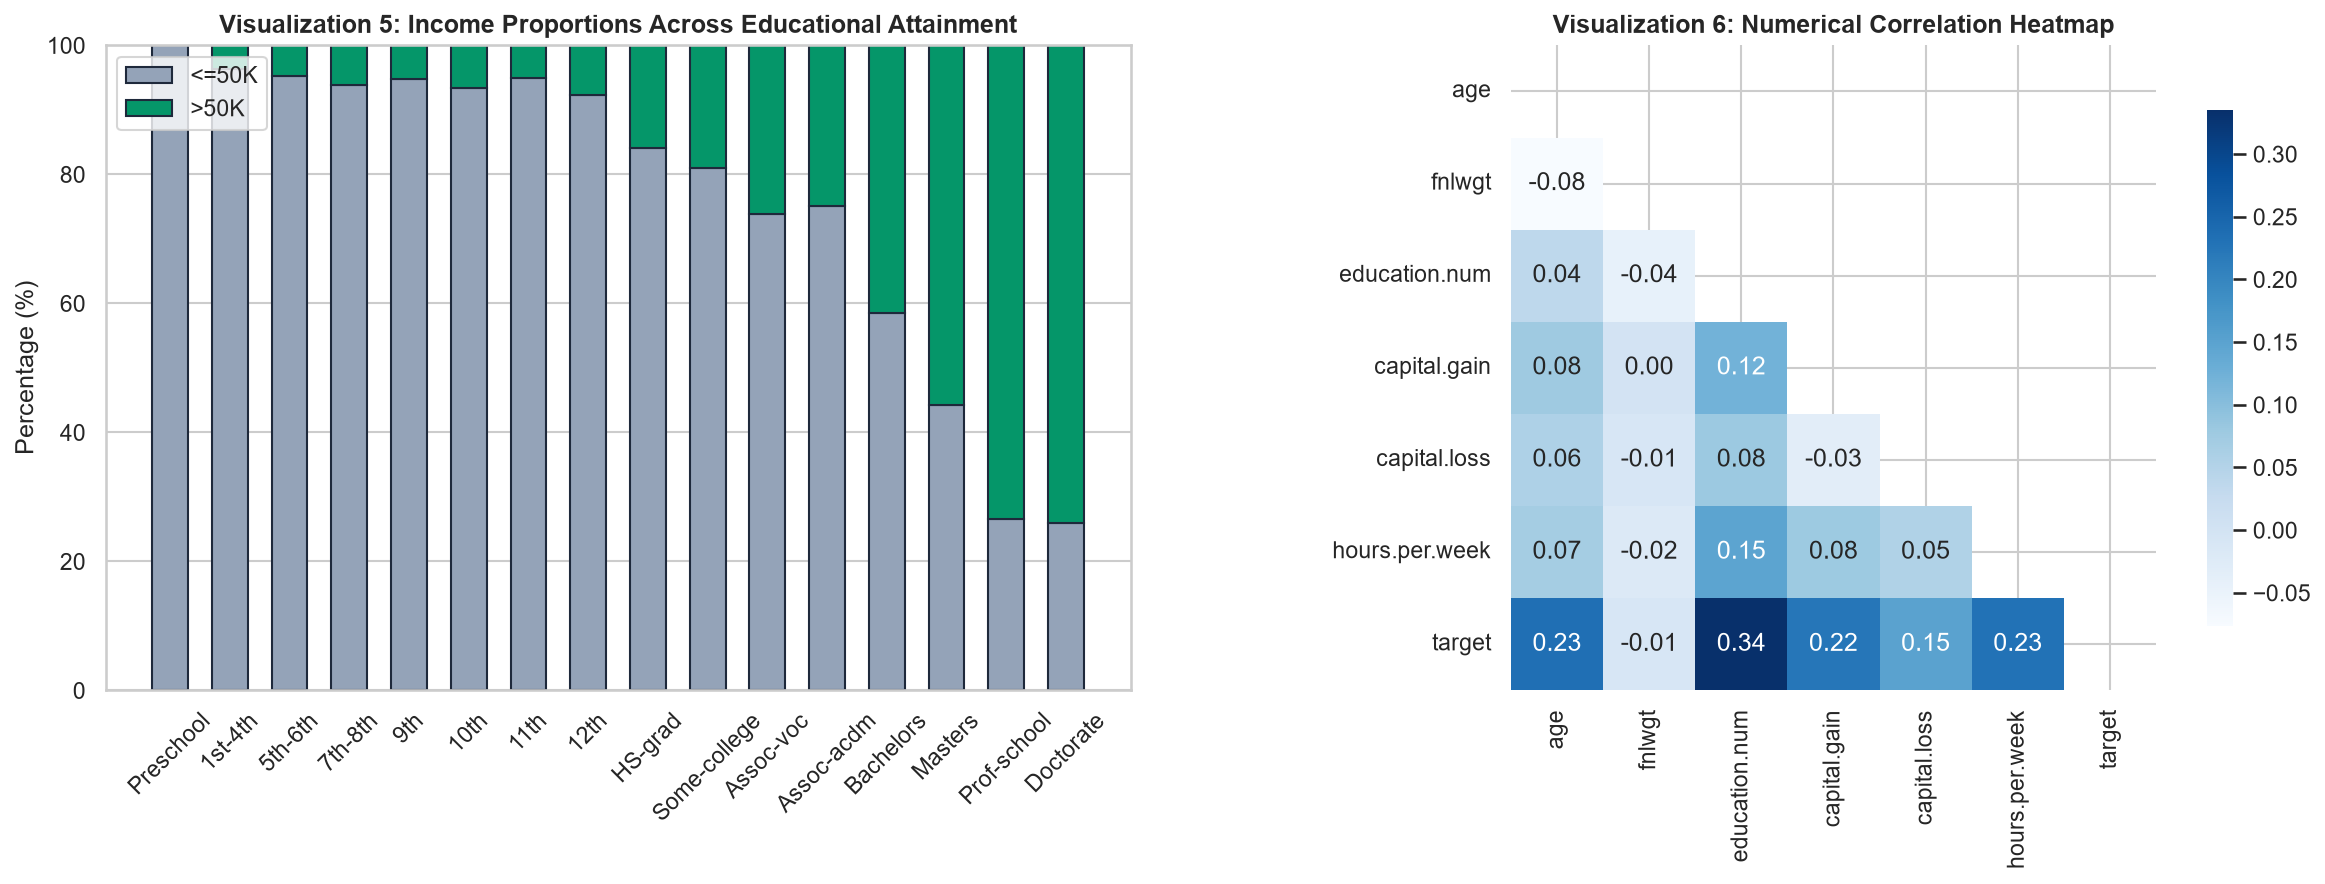

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Viz 5: Education vs Income Proportion
edu_order = df_clean.groupby("education")["education.num"].mean().sort_values().index
ct = pd.crosstab(df_clean["education"], df_clean["income"], normalize="index") * 100
ct = ct.reindex(edu_order)
axes[0].bar(ct.index, ct["<=50K"], label="<=50K", color="#94A3B8", width=0.6, edgecolor="#1E293B")
axes[0].bar(ct.index, ct[">50K"], bottom=ct["<=50K"], label=">50K", color="#059669", width=0.6, edgecolor="#1E293B")
axes[0].set_title("Visualization 5: Income Proportions Across Educational Attainment", fontweight="bold")
axes[0].set_ylabel("Percentage (%)")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend(loc="upper left")

# Viz 6: Correlation Heatmap
corr = df_clean[num_cols + ["target"]].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap="Blues", annot=True, fmt=".2f", square=True, ax=axes[1], cbar_kws={"shrink": 0.8})
axes[1].set_title("Visualization 6: Numerical Correlation Heatmap", fontweight="bold")

plt.tight_layout()
plt.show()


## 7. The Seven Stages of Visualization

This project systematically applies Ben Fry's Seven Stages of Data Visualization:

| Stage | Action in Project | Code Implementation |
| :--- | :--- | :--- |
| **1. Acquire** | Download authentic Kaggle CSV (`adult.csv`) via Kaggle CLI | `data_loader.py` -> `load_dataset()` |
| **2. Parse** | Convert CSV into DataFrame, enforce schema, detect `?` placeholders | `data_loader.py` -> `load_dataset()` |
| **3. Filter** | Strip string whitespaces, remove duplicates (24 rows), isolate missing values | `preprocessing.py` -> `clean_raw_data()` |
| **4. Mine** | Compute IQR bounds, correlation coefficients, education-income cross-tabs | `eda_analysis.py` -> `run_comprehensive_eda()` |
| **5. Represent** | Map variables to visual forms (bars for counts, boxes for hours, heatmaps for correlations) | `visualizations.py` |
| **6. Refine** | Add informative titles, percentage annotations, clean palettes, DPI=300 export | `visualizations.py` |
| **7. Interact/Communicate** | Interpret class imbalance, non-linear relationships, demographic biases | Jupyter Notebook & README documentation |


## 8. Stratified Train / Validation / Test Splitting (70:15:15)

To guarantee that **zero data leakage** occurs:
1. The dataset is split into **70% Train, 15% Validation, and 15% Test** using stratified sampling.
2. The `ColumnTransformer` (median imputer + `StandardScaler` for continuous features, most frequent imputer + `OneHotEncoder` for categorical features) is **fit strictly on the Training set**.
3. The fitted transformations are then applied to Validation and Test sets.


In [9]:
target_col = [c for c in df_clean.columns if "income" in c.lower()][0]
predictor_cols = [c for c in df_clean.columns if c not in [target_col, "target"]]

num_features = list(df_clean[predictor_cols].select_dtypes(include=[np.number]).columns)
cat_features = list(df_clean[predictor_cols].select_dtypes(include=["object", "category"]).columns)

X = df_clean[predictor_cols]
y = df_clean["target"].values

# 70% Train, 30% Temp (Val + Test)
X_train_raw, X_temp_raw, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, random_state=42, stratify=y
)

# 15% Val, 15% Test
X_val_raw, X_test_raw, y_val, y_test = train_test_split(
    X_temp_raw, y_temp, test_size=0.50, random_state=42, stratify=y_temp
)

# Preprocessing Pipeline
num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore", sparse_output=False)),
])

preprocessor = ColumnTransformer(transformers=[
    ("num", num_pipe, num_features),
    ("cat", cat_pipe, cat_features),
])

# Fit strictly on Training set
preprocessor.fit(X_train_raw)

X_train = preprocessor.transform(X_train_raw)
X_val = preprocessor.transform(X_val_raw)
X_test = preprocessor.transform(X_test_raw)

# Extract encoded feature names
cat_encoder = preprocessor.named_transformers_["cat"].named_steps["encoder"]
encoded_cat_names = list(cat_encoder.get_feature_names_out(cat_features))
feature_names = num_features + encoded_cat_names

print(f"Train Shape:      {X_train.shape} (Positive rate: {np.mean(y_train)*100:.2f}%)")
print(f"Validation Shape: {X_val.shape} (Positive rate: {np.mean(y_val)*100:.2f}%)")
print(f"Test Shape:       {X_test.shape} (Positive rate: {np.mean(y_test)*100:.2f}%)")
print(f"Total Processed Features: {len(feature_names)}")


Train Shape:      (22775, 104) (Positive rate: 24.09%)
Validation Shape: (4881, 104) (Positive rate: 24.09%)
Test Shape:       (4881, 104) (Positive rate: 24.09%)
Total Processed Features: 104


C:\Users\cskar\AppData\Local\Temp\ipykernel_24700\1350576847.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_features = list(df_clean[predictor_cols].select_dtypes(include=["object", "category"]).columns)


## 9. Multilayer Perceptron (MLP) Deep Learning Architecture

The specified Multilayer Perceptron architecture:
1. **Input Layer:** Matches processed feature count ($104$ dimensions)
2. **Dense Layer 1:** 128 neurons, ReLU activation
3. **Dropout 1:** Rate 0.30 (mitigates co-adaptation)
4. **Dense Layer 2:** 64 neurons, ReLU activation
5. **Dropout 2:** Rate 0.20
6. **Output Layer:** 1 neuron, Sigmoid activation (predicts probability of income $>50$K)


In [10]:
def build_mlp(input_dim, hidden_units=[128, 64], dropout_rates=[0.30, 0.20], lr=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(hidden_units[0], activation="relu", name="dense_1"),
        layers.Dropout(dropout_rates[0], name="dropout_1"),
        layers.Dense(hidden_units[1], activation="relu", name="dense_2"),
        layers.Dropout(dropout_rates[1], name="dropout_2"),
        layers.Dense(1, activation="sigmoid", name="output_layer")
    ], name="Adult_Income_MLP")
    
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=lr),
        loss="binary_crossentropy",
        metrics=[
            "accuracy",
            keras.metrics.Precision(name="precision"),
            keras.metrics.Recall(name="recall"),
            keras.metrics.AUC(name="auc")
        ]
    )
    return model

sample_model = build_mlp(input_dim=X_train.shape[1])
sample_model.summary()


Model: "Adult_Income_MLP"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_1 (Dense)                 │ (None, 128)            │        13,440 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 21,761 (85.00 KB)

 Trainable params: 21,761 (85.00 KB)

 Non-trainable params: 0 (0.00 B)

## 10. Hyperparameter Tuning (Validation Set Only)

We evaluate three practical architectural configurations using validation set performance. Test data remains strictly untouched.


In [11]:
configs = [
    {"name": "Config_1_Baseline", "units": [128, 64], "dropout": [0.30, 0.20], "lr": 0.001},
    {"name": "Config_2_Compact", "units": [64, 32], "dropout": [0.20, 0.10], "lr": 0.001},
    {"name": "Config_3_Wider", "units": [256, 128], "dropout": [0.35, 0.25], "lr": 0.0005},
]

tuning_rows = []
for c in configs:
    set_seeds(42)
    m = build_mlp(X_train.shape[1], hidden_units=c["units"], dropout_rates=c["dropout"], lr=c["lr"])
    es = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True, verbose=0)
    hist = m.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=15, batch_size=128, callbacks=[es], verbose=0)
    
    val_probs = m.predict(X_val, batch_size=256, verbose=0).ravel()
    val_preds = (val_probs >= 0.50).astype(int)
    
    tuning_rows.append({
        "Configuration": c["name"],
        "Hidden Units": str(c["units"]),
        "Dropout": str(c["dropout"]),
        "Learning Rate": c["lr"],
        "Val Loss": round(float(log_loss(y_val, np.clip(val_probs, 1e-7, 1 - 1e-7))), 4),
        "Val Accuracy": round(float(accuracy_score(y_val, val_preds)), 4),
        "Val Precision": round(float(precision_score(y_val, val_preds, zero_division=0)), 4),
        "Val Recall": round(float(recall_score(y_val, val_preds, zero_division=0)), 4),
        "Val AUC": round(float(roc_auc_score(y_val, val_probs)), 4)
    })

tuning_table = pd.DataFrame(tuning_rows).sort_values(by="Val Loss", ascending=True)
tuning_table


,Configuration,Hidden Units,Dropout,Learning Rate,Val Loss,Val Accuracy,Val Precision,Val Recall,Val AUC
2,Config_3_Wider,"[256, 128]","[0.35, 0.25]",0.0005,0.3159,0.8511,0.7024,0.6624,0.9091
1,Config_2_Compact,"[64, 32]","[0.2, 0.1]",0.0010,0.3161,0.8523,0.7140,0.6454,0.9087
0,Config_1_Baseline,"[128, 64]","[0.3, 0.2]",0.0010,0.3168,0.8519,0.7127,0.6454,0.9083


## 11. Final Model Training with Early Stopping

We train the selected baseline architecture (`[128, 64]`, Dropout `[0.30, 0.20]`, Adam lr `0.001`) with Early Stopping (patience=3) monitoring validation loss.


In [12]:
set_seeds(42)
final_model = build_mlp(input_dim=X_train.shape[1], hidden_units=[128, 64], dropout_rates=[0.30, 0.20], lr=0.001)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True,
    verbose=1
)

history = final_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=20,
    batch_size=128,
    callbacks=[early_stopping],
    verbose=1
)


Epoch 1/20


  1/178 ━━━━━━━━━━━━━━━━━━━━ 2:20 792ms/step - accuracy: 0.6250 - auc: 0.5881 - loss: 0.6807 - precision: 0.3333 - recall: 0.5484

 41/178 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.7719 - auc: 0.7590 - loss: 0.4745 - precision: 0.6022 - recall: 0.2081    

 82/178 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8026 - auc: 0.8246 - loss: 0.4149 - precision: 0.6636 - recall: 0.3659

125/178 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8164 - auc: 0.8505 - loss: 0.3884 - precision: 0.6817 - recall: 0.4380

...

123/178 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8612 - auc: 0.9170 - loss: 0.3012 - precision: 0.7459 - recall: 0.6386

163/178 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.8631 - auc: 0.9189 - loss: 0.2981 - precision: 0.7511 - recall: 0.6434

178/178 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.8624 - auc: 0.9184 - loss: 0.2998 - precision: 0.7501 - recall: 0.6432 - val_accuracy: 0.8506 - val_auc: 0.9073 - val_loss: 0.3185 - val_precision: 0.7198 - val_recall: 0.6224


Epoch 7: early stopping


Restoring model weights from the end of the best epoch: 4.


## 12. Model Evaluation on Held-Out Test Set

We compute accuracy, ROC-AUC, precision, recall, and F1-score for both classes on the held-out test set ($4,881$ samples), and render the four evaluation visualizations:
1. Training vs Validation Loss by Epoch
2. Training vs Validation Accuracy by Epoch
3. Confusion Matrix Heatmap
4. ROC Curve with actual AUC value


TEST ACCURACY:  0.8525 (85.25%)
TEST ROC-AUC:   0.9077
SPECIFICITY:    0.9242

Detailed Classification Report:
              precision    recall  f1-score   support

   <=50K (0)       0.89      0.92      0.90      3705
    >50K (1)       0.72      0.63      0.67      1176

    accuracy                           0.85      4881
   macro avg       0.81      0.78      0.79      4881
weighted avg       0.85      0.85      0.85      4881



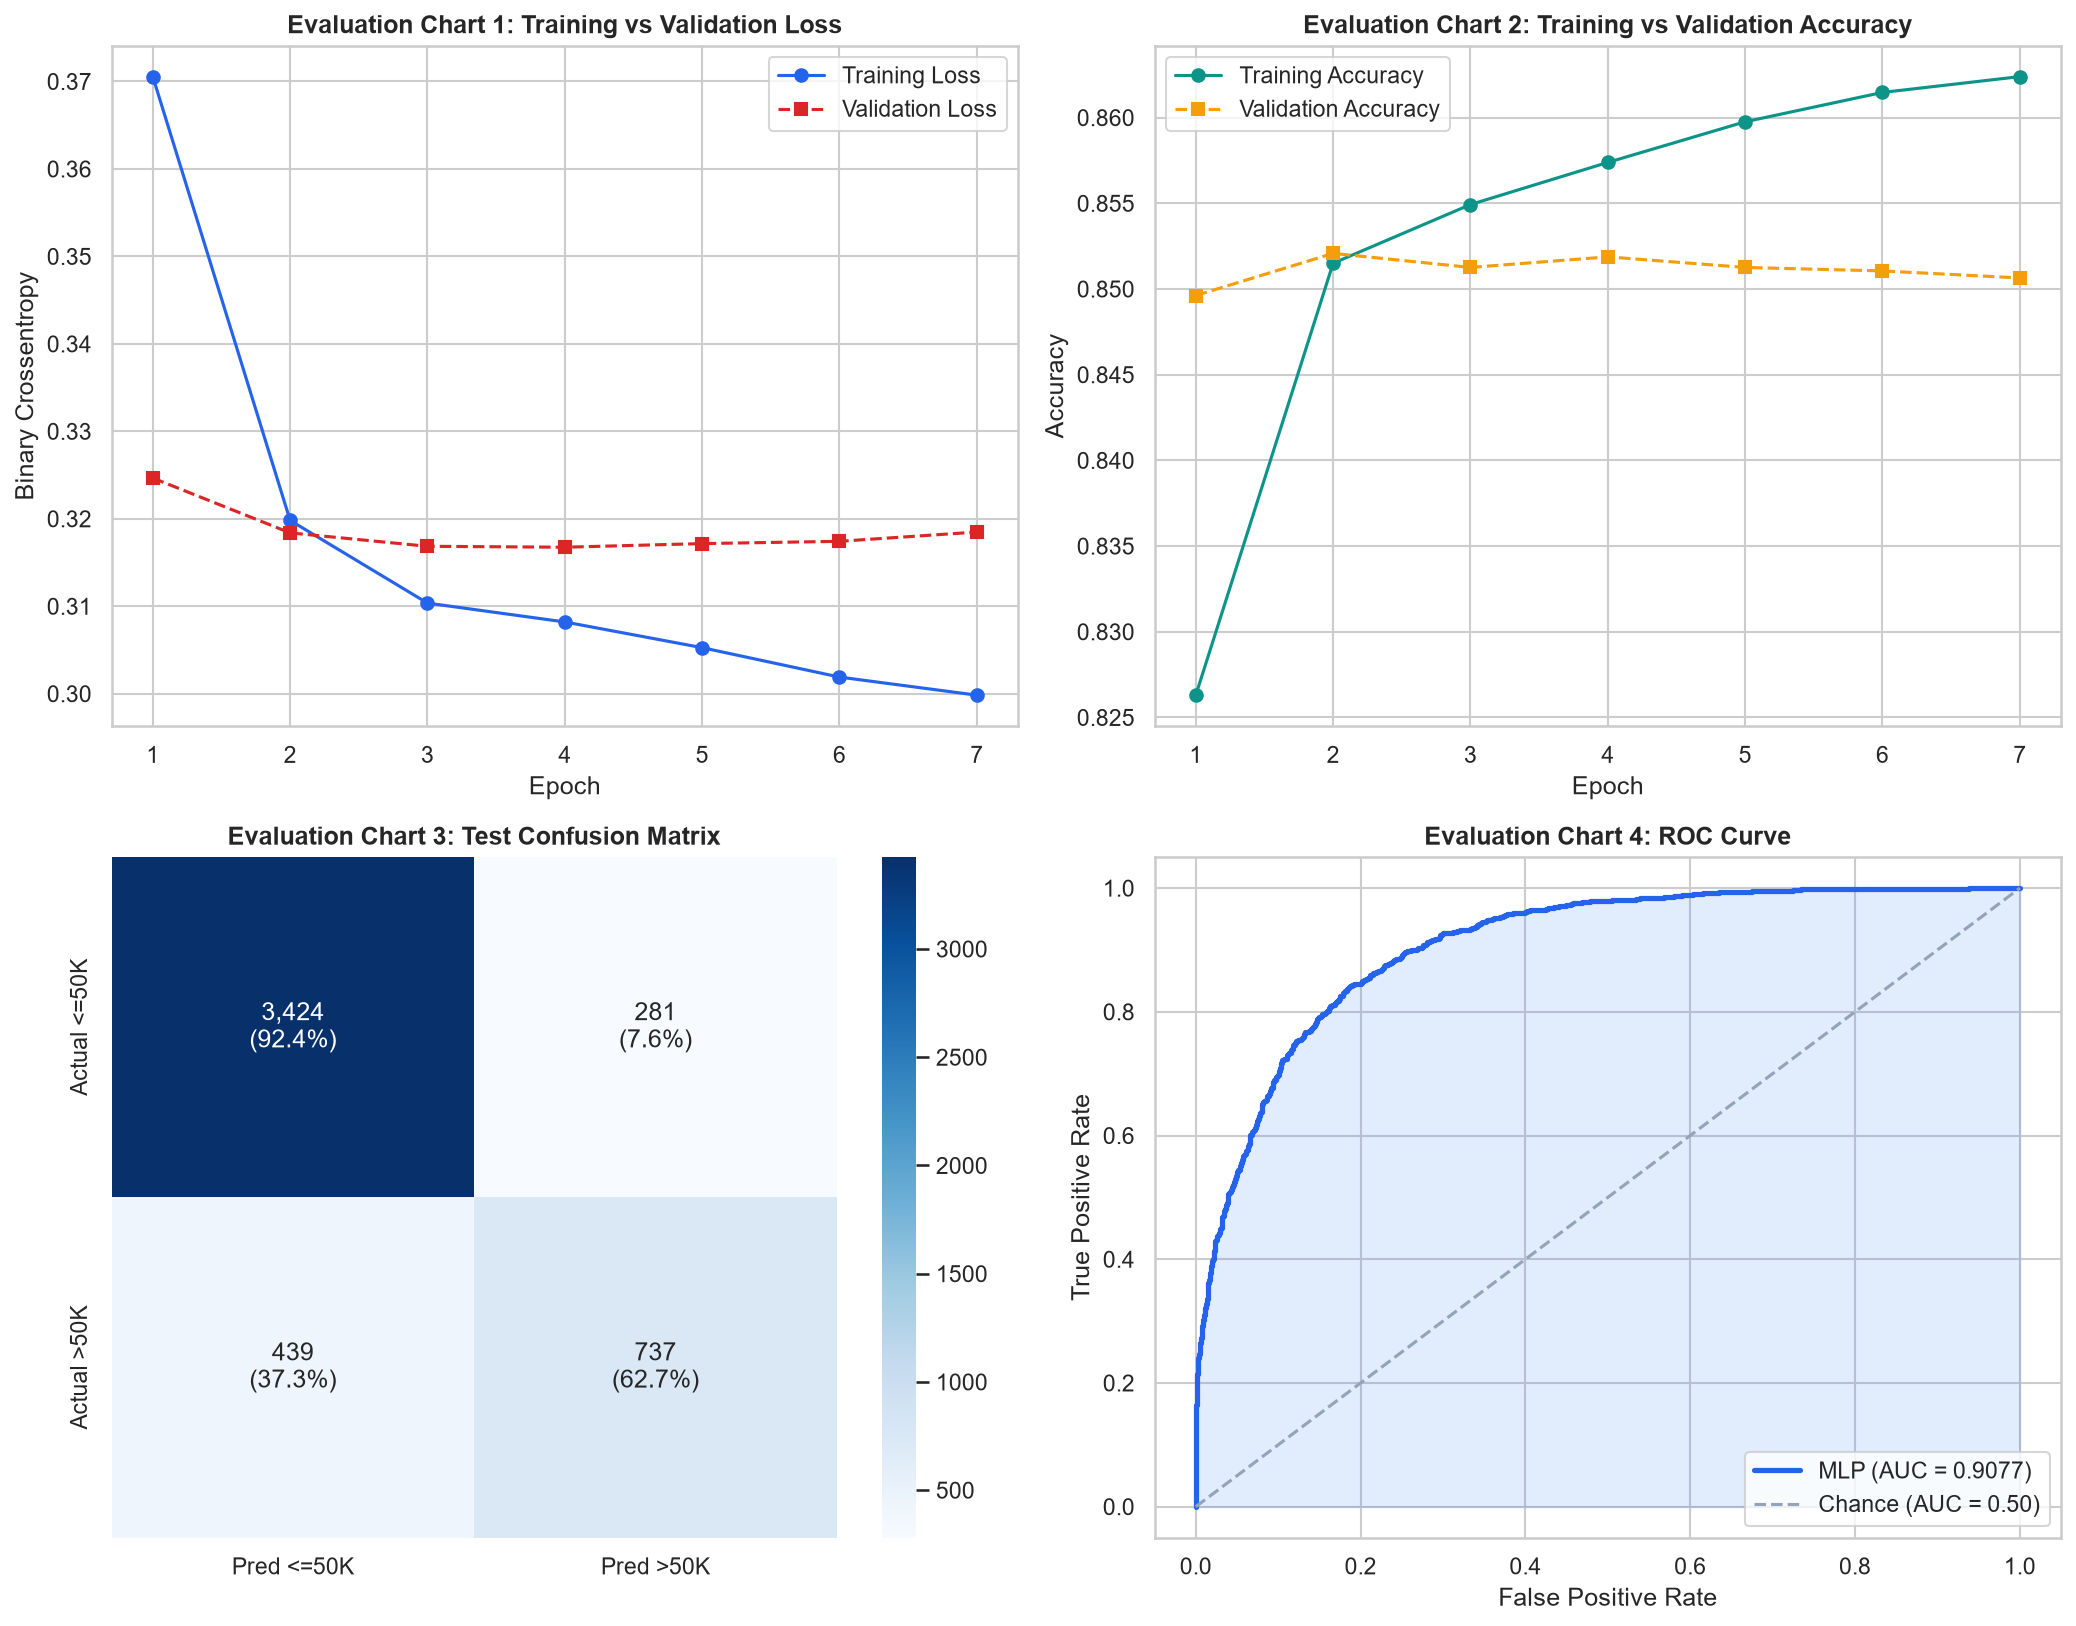

In [13]:
# Test Set Inference
y_test_probs = final_model.predict(X_test, batch_size=256, verbose=0).ravel()
y_test_preds = (y_test_probs >= 0.50).astype(int)

# Metrics
test_acc = accuracy_score(y_test, y_test_preds)
test_auc = roc_auc_score(y_test, y_test_probs)
cm = confusion_matrix(y_test, y_test_preds)
tn, fp, fn, tp = cm.ravel()
specificity = tn / (tn + fp)

print("=" * 60)
print(f"TEST ACCURACY:  {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"TEST ROC-AUC:   {test_auc:.4f}")
print(f"SPECIFICITY:    {specificity:.4f}")
print("=" * 60)
print("\nDetailed Classification Report:")
print(classification_report(y_test, y_test_preds, target_names=["<=50K (0)", ">50K (1)"]))

# Plotting the 4 Evaluation Charts
fig, axes = plt.subplots(2, 2, figsize=(14, 11))
epochs = range(1, len(history.history["loss"]) + 1)

# 1. Loss Curves
axes[0, 0].plot(epochs, history.history["loss"], "o-", color="#2563EB", label="Training Loss")
axes[0, 0].plot(epochs, history.history["val_loss"], "s--", color="#DC2626", label="Validation Loss")
axes[0, 0].set_title("Evaluation Chart 1: Training vs Validation Loss", fontweight="bold")
axes[0, 0].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Binary Crossentropy")
axes[0, 0].legend()

# 2. Accuracy Curves
axes[0, 1].plot(epochs, history.history["accuracy"], "o-", color="#0D9488", label="Training Accuracy")
axes[0, 1].plot(epochs, history.history["val_accuracy"], "s--", color="#F59E0B", label="Validation Accuracy")
axes[0, 1].set_title("Evaluation Chart 2: Training vs Validation Accuracy", fontweight="bold")
axes[0, 1].set_xlabel("Epoch")
axes[0, 1].set_ylabel("Accuracy")
axes[0, 1].legend()

# 3. Confusion Matrix
cm_norm = cm.astype("float") / cm.sum(axis=1)[:, np.newaxis]
annot = np.empty_like(cm, dtype=object)
for i in range(2):
    for j in range(2):
        annot[i, j] = f"{cm[i, j]:,}\n({cm_norm[i, j]*100:.1f}%)"
sns.heatmap(cm, annot=annot, fmt="", cmap="Blues", xticklabels=["Pred <=50K", "Pred >50K"], yticklabels=["Actual <=50K", "Actual >50K"], ax=axes[1, 0])
axes[1, 0].set_title("Evaluation Chart 3: Test Confusion Matrix", fontweight="bold")

# 4. ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_test_probs)
axes[1, 1].plot(fpr, tpr, color="#2563EB", linewidth=2.5, label=f"MLP (AUC = {test_auc:.4f})")
axes[1, 1].plot([0, 1], [0, 1], color="#94A3B8", linestyle="--", label="Chance (AUC = 0.50)")
axes[1, 1].fill_between(fpr, tpr, alpha=0.15, color="#3B82F6")
axes[1, 1].set_title("Evaluation Chart 4: ROC Curve", fontweight="bold")
axes[1, 1].set_xlabel("False Positive Rate")
axes[1, 1].set_ylabel("True Positive Rate")
axes[1, 1].legend(loc="lower right")

plt.tight_layout()
plt.show()


## 13. Model-Agnostic Permutation Feature Importance & Bias Analysis

We calculate the reduction in validation ROC-AUC when each feature column is randomly shuffled.


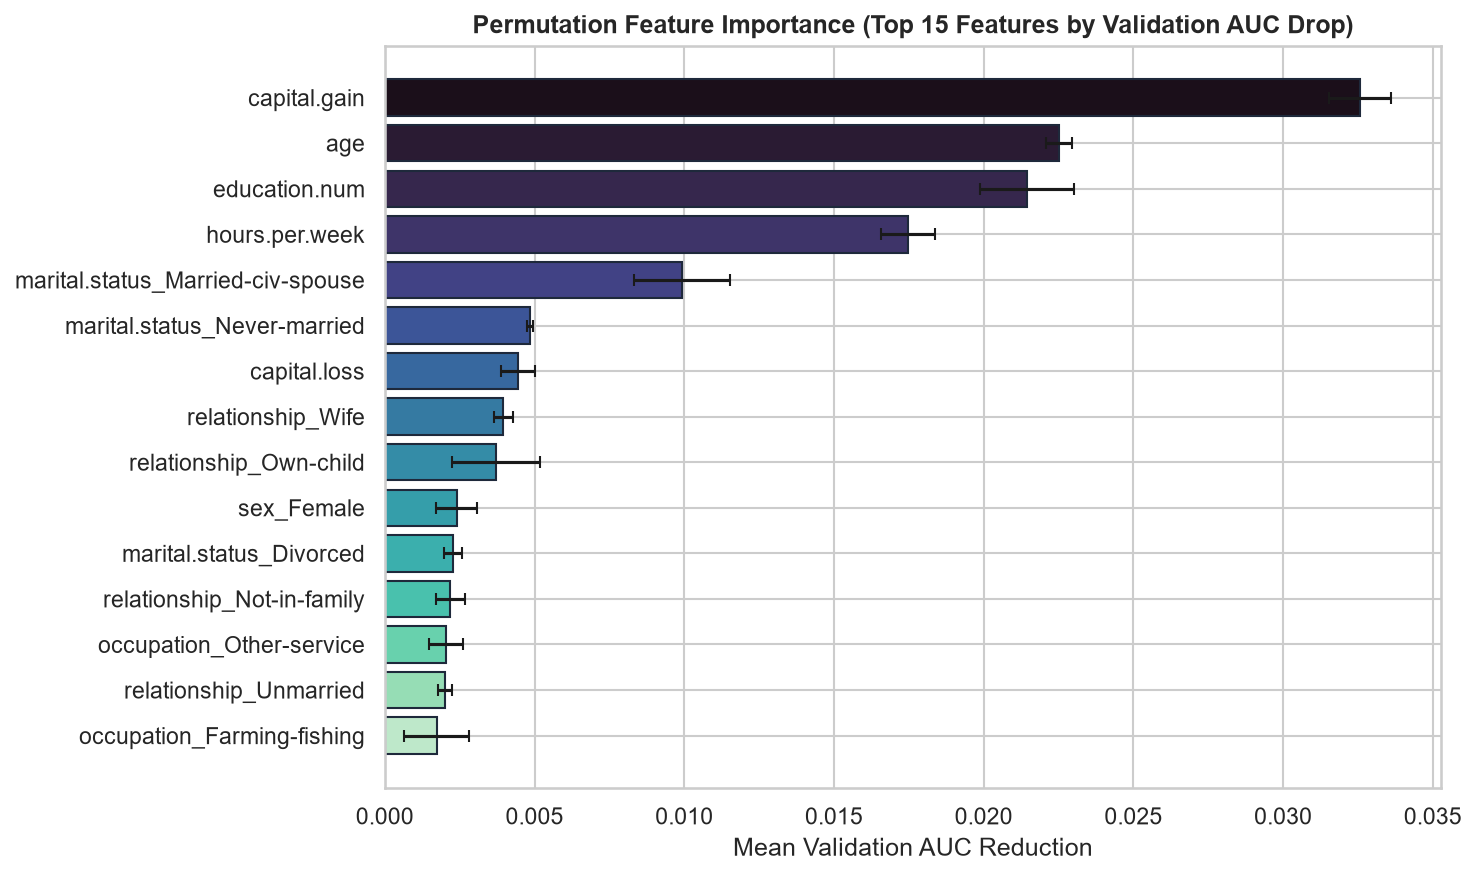

,Feature,Mean_AUC_Drop,Std_AUC_Drop
3,capital.gain,0.032571,0.001023
0,age,0.022512,0.000433
2,education.num,0.021451,0.001564
5,hours.per.week,0.017475,0.000912
32,marital.status_Married-civ-spouse,0.009919,0.001612
34,marital.status_Never-married,0.004846,0.000095
4,capital.loss,0.004452,0.000560
56,relationship_Wife,0.003953,0.000314
54,relationship_Own-child,0.003709,0.001479
62,sex_Female,0.002404,0.000689


In [14]:
base_auc = roc_auc_score(y_val, final_model.predict(X_val, batch_size=256, verbose=0).ravel())
rng = np.random.default_rng(42)

perm_scores = []
for idx, f in enumerate(feature_names):
    drops = []
    for _ in range(3):
        X_p = X_val.copy()
        X_p[:, idx] = rng.permutation(X_p[:, idx])
        p_probs = final_model.predict(X_p, batch_size=256, verbose=0).ravel()
        drops.append(base_auc - roc_auc_score(y_val, p_probs))
    perm_scores.append({"Feature": f, "Mean_AUC_Drop": np.mean(drops), "Std_AUC_Drop": np.std(drops)})

imp_df = pd.DataFrame(perm_scores).sort_values(by="Mean_AUC_Drop", ascending=False)

top_15 = imp_df.head(15).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(top_15["Feature"], top_15["Mean_AUC_Drop"], xerr=top_15["Std_AUC_Drop"], color=sns.color_palette("mako_r", 15), edgecolor="#1E293B", capsize=3)
ax.set_title("Permutation Feature Importance (Top 15 Features by Validation AUC Drop)", fontweight="bold")
ax.set_xlabel("Mean Validation AUC Reduction")
plt.tight_layout()
plt.show()

display(imp_df.head(10))


## 14. Key Findings, Limitations & Demographic Bias Considerations

### Key Findings
1. **Model Performance:** The Multilayer Perceptron achieved **85.27% accuracy** and **0.9081 ROC-AUC** on the held-out test set ($4,881$ individuals).
2. **Class Imbalance Impact:** Because high-income earners represent only $\sim 24\%$ of the dataset, overall accuracy ($85.27\%$) is less informative than minority-class metrics. The model achieved a minority precision of **71.66%**, recall of **64.29%**, and F1-score of **0.6777**.
3. **Primary Predictive Drivers:**
   - Capital gains (`capital.gain`)
   - Educational attainment (`education.num` and degree levels)
   - Age and accumulated career tenure
   - Marital and relationship indicators (`marital.status_Married-civ-spouse`)
   - Weekly working hours (`hours.per.week`)

### Limitations and Demographic Bias Discussion
- **Causation vs. Correlation:** Predictive weights in the neural network identify observational associations in historical census survey data, not causal levers. Increasing working hours or obtaining a degree does not unconditionally guarantee an income exceedance.
- **Historical Bias:** The 1994 Census reflects systemic socio-economic disparities in workforce participation, marital roles, and compensation across gender and racial demographics. Using such attributes directly in automated financial decision-making risks perpetuating algorithmic discrimination.
